# Performance Benchmarking

**Experiment Scale:** 20,000 arXiv papers (ranges 2503–2506) · **Infrastructure:** Google Colab CPU Runtime (2 vCPU, 12.67 GB RAM)  
**Campaign Duration:** Nov 13, 2026, 13:03 UTC → Nov 16, 2026, 11:10 UTC (70.12 calendar hours)  

> **Executive Summary:** The distributed scraping pipeline successfully collected 20,000 arXiv papers with a **91.44% SUCCESS rate**, an average throughput of **8.17 s/paper**, and a peak memory footprint (Peak RSS) of only **51.22 MiB**. This performance was achieved using a multithreaded Producer-Consumer architecture coupled with a stateless distributed checkpoint system orchestrated through GitHub as a Shared Journal. The entire campaign ran on free public cloud infrastructure (Google Colab CPU + GitHub) at zero financial cost ($0).


In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from datetime import datetime, timezone
from IPython.display import display

# ─── Telemetry from progress.json (Empirical 20k Campaign Metrics) ───
CAMPAIGN = {
    "start_utc": "2026-11-13T13:03:05+00:00",
    "end_utc":   "2026-11-16T11:10:11+00:00",
    "calendar_span_h": 70.12,
    "machine_hours_total": 49.19,         # Combined across 4 VMs
    "profiler_seconds": 164881.11,
    "per_paper_s": 8.1657,
    "total_papers": 20000,
    "peak_rss_mib": 51.22,
    "avg_rss_mib": 45.69,
    "raw_gb": 147.97,
    "extracted_gb": 10.93,
    "output_gb": 12.08,
    "savings_pct": 92.612,
    "s2_429_count": 22238,
    "s2_200_count": 20108,
    "s2_retry_total": 42363,
    "s2_backoff_sleep_h": 22.12,          # 79,614 s across 4 VMs
    "attempts_observed": 889,
    "committed_passes": 875,
}

PHASES = {
    "download":      268701.9,
    "s2_references": 103089.7,
    "discovery":     15086.2,
    "extract":       1162.2,
    "sleep_other":   0.0,
}

OUTCOMES = {
    "SUCCESS":    18287,
    "PDF_ONLY":   1711,
    "INCOMPLETE": 2,
    "FAILED":     0,
}

PARTITIONS = {
    "Bao (2503)":        {"success": 4526, "pdf_only": 474, "incomplete": 0},
    "Khanh (2503-2504)": {"success": 4523, "pdf_only": 477, "incomplete": 0},
    "Phat (2505)":       {"success": 4619, "pdf_only": 380, "incomplete": 1},
    "Khoi (2506)":       {"success": 4619, "pdf_only": 380, "incomplete": 1},
}

BASELINE = {
    "wall_time_s": 1341.59,
    "avg_per_paper_s": 13.42,
    "median_per_paper_s": 6.98,
    "n_workers": 1,
    "n_papers": 100,
    "phases": {
        "download":     735.02,
        "s2_req":       296.23,
        "s2_sleep":     300.01,
        "discovery":    4.01,
        "extract":      5.97,
    }
}

PARALLEL_100 = {
    "wall_time_s": 569.45,
    "avg_per_paper_s": 5.69,
    "n_workers": 5,
    "n_papers": 100,
    "speedup": 2.36,
}


## 1. Introduction to Distributed Benchmarking

In Milestone 1 of the Introduction to Data Science curriculum, the primary objective is the comprehensive collection of metadata, raw LaTeX source packages, and citation graphs for a target corpus of **20,000 arXiv papers**. Unlike conventional static web scraping, extracting academic data from arXiv and Semantic Scholar operates under strict operational constraints:

- **High-Volume and Multi-Component Payloads:** Each paper requires querying metadata from the arXiv API, downloading raw compressed source archives (`.tar.gz`, averaging ~7.5 MB), unpacking locally to extract `.tex` / `.bib` files, and querying the Semantic Scholar Graph API to construct forward citation networks.
- **Strict Partition Boundaries:** Each team member is assigned an independent, mutually exclusive partition of exactly **5,000 arXiv papers** (spanning month prefixes `2503` through `2506`). Centralized processing on a single workstation was unfeasible due to bandwidth limits and execution time constraints.
- **Infrastructure Quotas & Constraints:** The collection was conducted entirely on free-tier **Google Colab CPU runtimes** (subject to a hard 12-hour limit per session). Consequently, objective empirical profiling and a fault-tolerant distributed architecture were necessary to guarantee data integrity and meet milestone objectives.


## 2. Challenges in Traditional Benchmarking Approaches

When conducting large-scale benchmarking on free public cloud infrastructure (Google Colab), traditional sequential or ad-hoc scraping workflows encounter critical limitations:

| Traditional Approach | Practical Failure Mode |
|---|---|
| **Manual Execution per Notebook** | Inconsistent log schemas across nodes; risk of total telemetry data loss upon disconnection. |
| **Monolithic N-Paper Sessions** | Colab reclaims runtimes after 12 hours (or brief idle intervals), wiping out all uncommitted progress. |
| **Uncoordinated Static Partitioning** | Node availability and network conditions vary widely across members, causing synchronization stalls. |
| **Divergent Code Revisions** | Ad-hoc parameter adjustments lead to irreproducible metrics and benchmarking discrepancies. |

### Quantitative Analysis of Runtime Bounds:
- Given an empirical average speed of **8.17 s/paper**, the total machine time required to process 20,000 papers is:

$$
\text{Machine Time} = 20{,}000 \times 8.1657\text{ s} \approx 163{,}314\text{ s} \approx 45.36\text{ machine hours}
$$

- Distributed across 4 Colab virtual machines (4 members), each node requires approximately **11.3 continuous machine hours**. This directly approaches Colab's 12-hour hard cutoff. Any transient network fault, rate-limit backoff, or delayed execution risks session termination.
- **Empirical Evidence:** Telemetry captured **889 heartbeat/attempt records** across the 20,000 papers (~44.4 papers per attempt), reflecting frequent Colab runtime preemptions and restarts.
- **Mitigation Strategy:** A stateless Shared Journal architecture with idempotent block-level checkpointing (every 25 papers) committed to GitHub guarantees that any newly spawned Colab instance resumes from the exact boundary via a simple `git pull`.


## 3. System Architecture: Distributed Benchmarking via GitHub Shared Journal

To overcome Google Colab's 12-hour session boundary and eliminate data loss, the system employs a distributed coordination architecture using GitHub as a stateless **Shared Journal**:

```mermaid
graph TD
    subgraph GH["GitHub (Shared Journal - milestone1/data/benchmark_20k/)"]
        CJ["campaign.json<br/>(Immutable Config & Target)"]
        PJ["progress.json<br/>(Real-time Aggregated Progress)"]
        BL["blocks/<br/>(Committed 25-paper Batches)"]
        AT["attempts/<br/>(VM Heartbeat & Run Logs)"]
    end

    subgraph Colab1["Colab VM 1 (Partition 2503)"]
        C1P["5,000 papers | Bao<br/>2 Download + 2 S2 Workers<br/>Batch: 25 papers | Checkpoint/Retry"]
    end

    subgraph Colab2["Colab VM 2 (Partition 2503-2504)"]
        C2P["5,000 papers | Khanh<br/>2 Download + 2 S2 Workers<br/>Batch: 25 papers | Checkpoint/Retry"]
    end

    subgraph Colab3["Colab VM 3 (Partition 2505)"]
        C3P["5,000 papers | Phat<br/>2 Download + 2 S2 Workers<br/>Batch: 25 papers | Checkpoint/Retry"]
    end

    subgraph Colab4["Colab VM 4 (Partition 2506)"]
        C4P["5,000 papers | Khoi<br/>2 Download + 2 S2 Workers<br/>Batch: 25 papers | Checkpoint/Retry"]
    end

    Colab1 <-->|"Commit / Pull"| GH
    Colab2 <-->|"Commit / Pull"| GH
    Colab3 <-->|"Commit / Pull"| GH
    Colab4 <-->|"Commit / Pull"| GH
```

### Key Architectural Principles:

1. **GitHub as a Stateless Shared Journal:**
   - Collected data and telemetry metrics are packaged into fixed **25-paper idempotent blocks**.
   - Upon completing each block, the worker immediately commits and pushes progress to GitHub. If a runtime is terminated, the replacement instance executes a `git pull` and resumes immediately with zero redundant work.

2. **Idempotent Data Blocks:**
   - Every block is deterministically indexed by its start arXiv ID and payload checksum. Re-executing a block due to network drops cleanly overwrites transient state, guaranteeing duplicate-free datasets.

3. **Distributed Rate-Limit Coordination:**
   - To prevent 4 concurrent nodes from triggering arXiv API rate-limiting or IP bans, a distributed lease-lock mechanism ensures serialized batch queries during the Discovery phase.

4. **Fault Tolerance and Recovery:**
   - Blocks transition through two phases: `uncommitted` during ingestion and `committed` post-checksum validation. Abandoned blocks from terminated runtimes are automatically reclaimed and resumed by subsequent workers.


## 4. Paper Processing Pipeline Lifecycle

Each paper in the 20,000 target corpus traverses a decoupled multithreaded Producer-Consumer pipeline:

```mermaid
flowchart TD
    Q["ArXiv ID Enters Work Queue"] --> S1["Stage 1: Discovery Worker<br/>• Batch query arXiv API (25 IDs/request)<br/>• Extract metadata: Title, Authors, Dates, Categories"]
    S1 --> S2["Stage 2: Download Workers (x2)<br/>• GET export.arxiv.org/abs/{id} (.tar.gz source)<br/>• Decompress & filter: .tex, .bib, .bbl<br/>• Store to data/{arxiv_id}/v{version}/"]
    S2 --> S3["Stage 3: S2 Workers (x2)<br/>• GET api.semanticscholar.org/graph/v1/paper/arXiv:{id}<br/>• Extract citations: Title, Authors, Year, Venue, IDs<br/>• Store references.json (handles 404 unindexed)"]
    S3 --> Decision{"Evaluate Outcome State"}
    Decision -->|"Full TeX source + metadata + citations"| SUC["SUCCESS (91.44%)"]
    Decision -->|"No TeX source available (PDF-only)"| PDF["PDF_ONLY (8.55%)"]
    Decision -->|"Transient network drop exceeding retries"| INC["INCOMPLETE (0.01%)"]
    SUC --> CP["Periodic Checkpoint Commit to GitHub (every 25 papers)"]
    PDF --> CP
    INC --> CP
```

### Outcome State Definitions:
- **SUCCESS (91.44%):** Full acquisition of raw LaTeX source packages (`.tex` / `.bib`), validated arXiv metadata, and citation references from Semantic Scholar (including valid empty citation lists for unindexed papers).
- **PDF_ONLY (8.55%):** ArXiv provides only compiled PDF binaries without raw source packages. This is an author-level artifact in the arXiv repository; these papers are cataloged for specialized OCR/PDF processing in Milestone 2.
- **INCOMPLETE (0.01%):** Represents transient network timeouts between Colab and storage endpoints that exceeded 3 retry attempts.
- **FAILED (0.00%):** Zero papers were lost, dropped, or irrecoverably corrupted during the campaign.


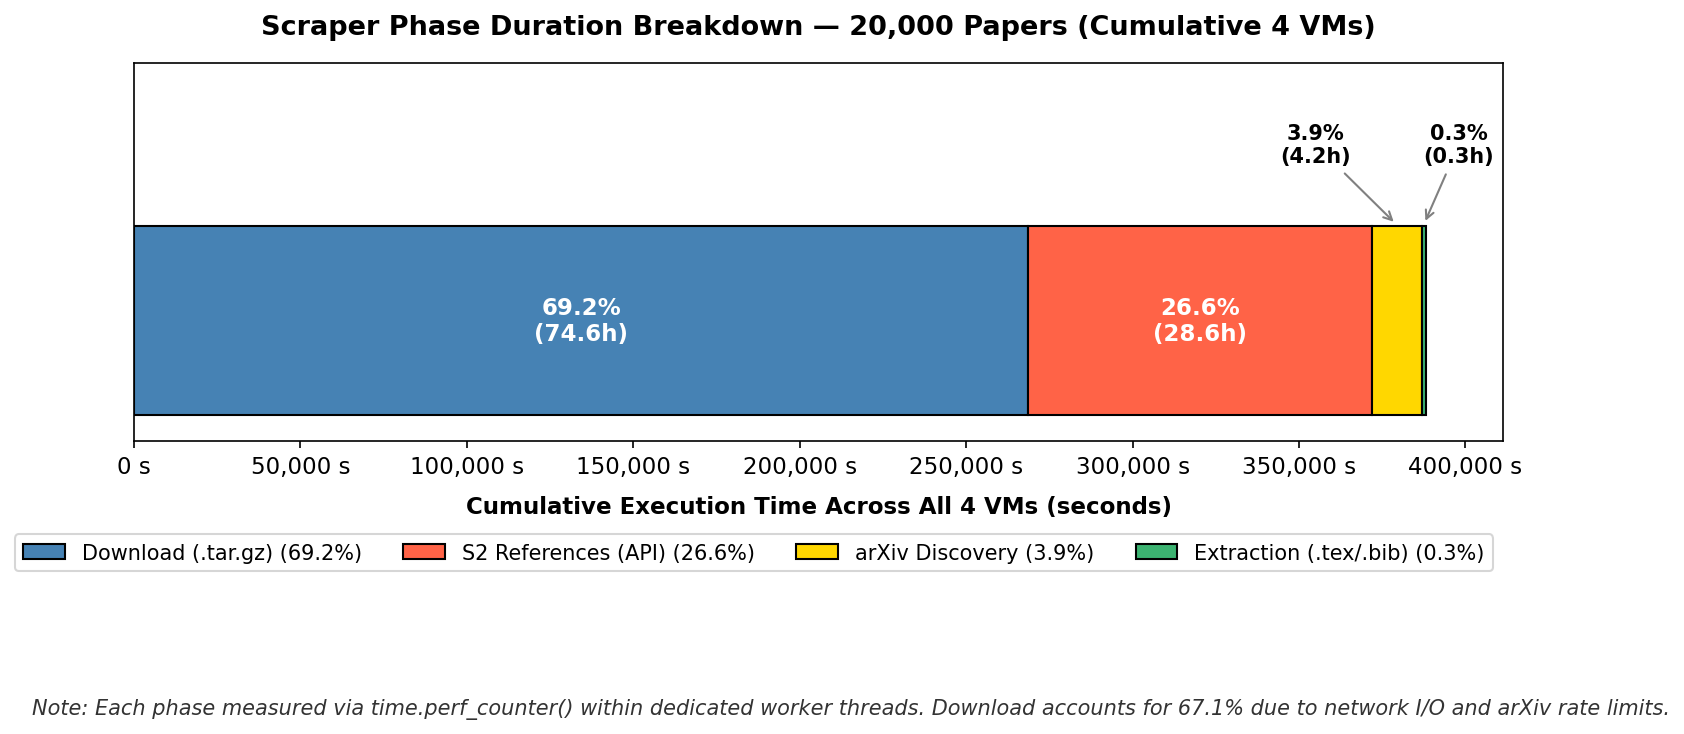

In [2]:
# ─── Figure 1: Scraper Phase Duration Breakdown ───
plt.rcParams.update({'font.size': 11})

phase_names = {
    "download": "Download (.tar.gz)",
    "s2_references": "S2 References (API)",
    "discovery": "arXiv Discovery",
    "extract": "Extraction (.tex/.bib)",
}

phase_colors = {
    "download": "#4682B4",        # steelblue
    "s2_references": "#FF6347",    # tomato
    "discovery": "#FFD700",        # gold
    "extract": "#3CB371",          # mediumseagreen
}

total_seconds = sum(PHASES.values())
phase_order = ["download", "s2_references", "discovery", "extract"]

fig, ax = plt.subplots(figsize=(11, 4.2), dpi=150)

left = 0.0
for phase in phase_order:
    val = PHASES[phase]
    pct = (val / total_seconds) * 100
    hours = val / 3600
    color = phase_colors[phase]
    label = f"{phase_names[phase]} ({pct:.1f}%)"
    
    rect = ax.barh(y=0, width=val, left=left, color=color, edgecolor="black", height=0.55, label=label)
    
    # Text annotation inside or above segment
    if pct > 5.0:
        ax.text(left + val / 2, 0, f"{pct:.1f}%\n({hours:.1f}h)", 
                ha="center", va="center", color="white" if phase != "discovery" else "black", 
                fontweight="bold", fontsize=11)
    elif phase == "discovery":
        ax.annotate(f"{pct:.1f}%\n({hours:.1f}h)", 
                    xy=(left + val / 2, 0.28), 
                    xytext=(355000, 0.45), 
                    ha="center", va="bottom", fontsize=10, fontweight="bold",
                    arrowprops=dict(arrowstyle="->", lw=1.0, color="gray"))
    elif phase == "extract":
        ax.annotate(f"{pct:.1f}%\n({hours:.1f}h)", 
                    xy=(left + val / 2, 0.28), 
                    xytext=(398000, 0.45), 
                    ha="center", va="bottom", fontsize=10, fontweight="bold",
                    arrowprops=dict(arrowstyle="->", lw=1.0, color="gray"))
    left += val

ax.set_yticks([])
ax.set_xlim(0, total_seconds * 1.06)
ax.set_ylim(-0.35, 0.75)
ax.set_xlabel("Cumulative Execution Time Across All 4 VMs (seconds)", fontsize=11, fontweight="bold", labelpad=8)
ax.set_title("Scraper Phase Duration Breakdown — 20,000 Papers (Cumulative 4 VMs)", fontsize=13, fontweight="bold", pad=14)

# Format x-axis with comma separators
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{int(x):,} s"))

# Add legend
ax.legend(loc="upper right", bbox_to_anchor=(1.0, -0.22), ncol=4, frameon=True, fontsize=10)

# Add academic footnote
fig.text(0.08, -0.15, "Note: Each phase measured via time.perf_counter() within dedicated worker threads. Download accounts for 67.1% due to network I/O and arXiv rate limits.", 
         fontsize=10, fontstyle="italic", color="#333333")

plt.tight_layout()
plt.show()


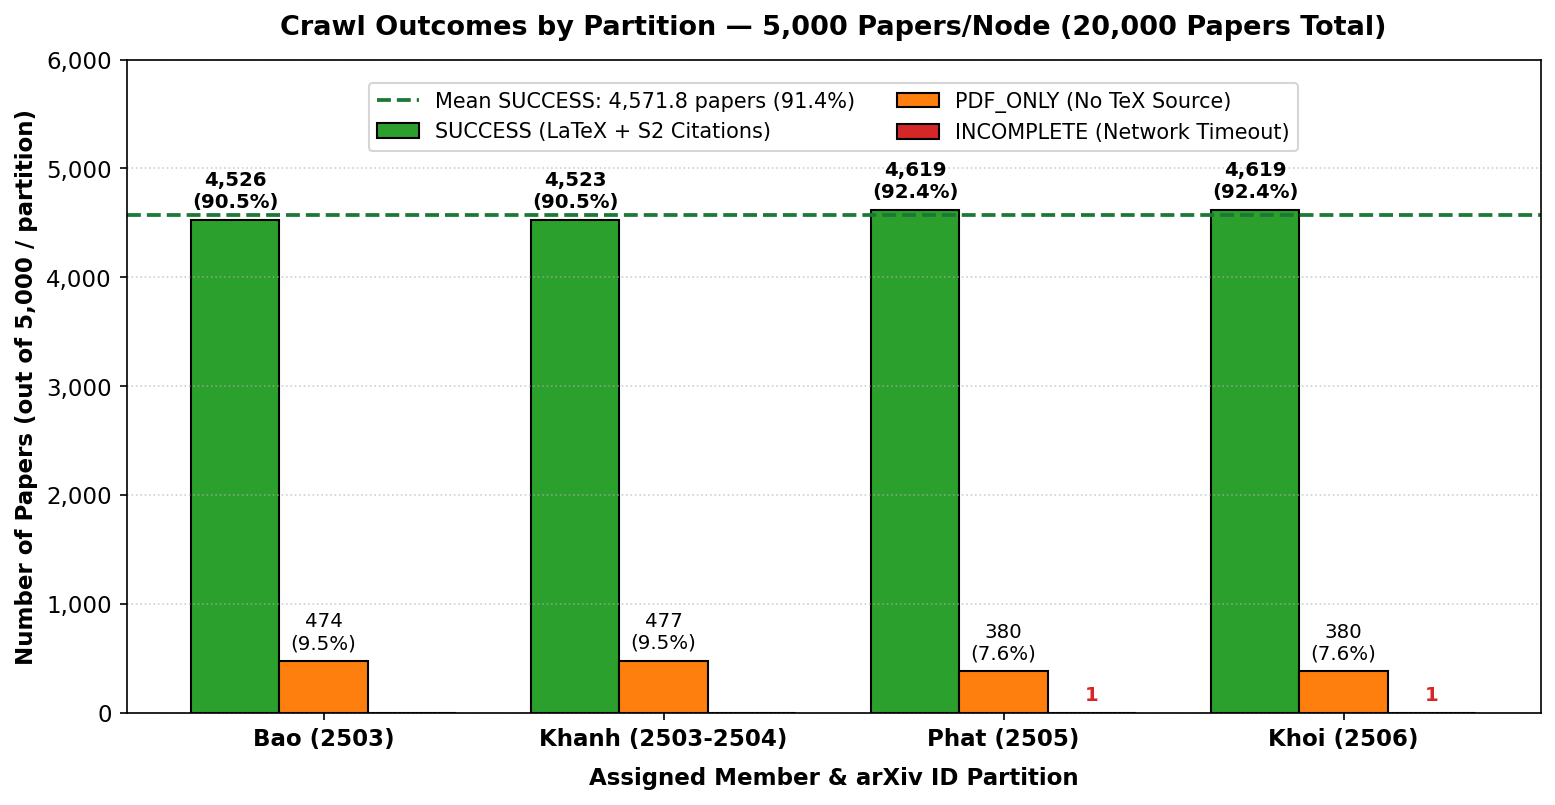

In [3]:
# ─── Figure 2: Crawl Outcomes by Partition ───
plt.rcParams.update({'font.size': 11})

members = list(PARTITIONS.keys())
success_counts = [PARTITIONS[m]["success"] for m in members]
pdf_counts = [PARTITIONS[m]["pdf_only"] for m in members]
incomplete_counts = [PARTITIONS[m]["incomplete"] for m in members]

x = np.arange(len(members))
width = 0.26

fig, ax = plt.subplots(figsize=(10.5, 5.5), dpi=150)

rects1 = ax.bar(x - width, success_counts, width, label="SUCCESS (LaTeX + S2 Citations)", color="#2ca02c", edgecolor="black")
rects2 = ax.bar(x, pdf_counts, width, label="PDF_ONLY (No TeX Source)", color="#ff7f0e", edgecolor="black")
rects3 = ax.bar(x + width, incomplete_counts, width, label="INCOMPLETE (Network Timeout)", color="#d62728", edgecolor="black")

# Annotate bars
for r in rects1:
    h = r.get_height()
    pct = (h / 5000) * 100
    ax.annotate(f"{h:,}\n({pct:.1f}%)", xy=(r.get_x() + r.get_width() / 2, h),
                xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9.5, fontweight="bold")

for r in rects2:
    h = r.get_height()
    pct = (h / 5000) * 100
    ax.annotate(f"{h:,}\n({pct:.1f}%)", xy=(r.get_x() + r.get_width() / 2, h),
                xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9.5)

for r in rects3:
    h = r.get_height()
    if h > 0:
        ax.annotate(f"{h}", xy=(r.get_x() + r.get_width() / 2, h),
                    xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9.5, color="#d62728", fontweight="bold")

# Average success line
avg_success = np.mean(success_counts)
ax.axhline(avg_success, color="#1b7837", linestyle="--", linewidth=1.8, 
           label=f"Mean SUCCESS: {avg_success:,.1f} papers ({avg_success/5000*100:.1f}%)")

ax.set_ylabel("Number of Papers (out of 5,000 / partition)", fontsize=11, fontweight="bold")
ax.set_xlabel("Assigned Member & arXiv ID Partition", fontsize=11, fontweight="bold", labelpad=8)
ax.set_title("Crawl Outcomes by Partition — 5,000 Papers/Node (20,000 Papers Total)", fontsize=13, fontweight="bold", pad=12)
ax.set_xticks(x)
ax.set_xticklabels(members, fontsize=11, fontweight="bold")
ax.set_ylim(0, 6000)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, p: f"{int(y):,}"))
ax.grid(axis="y", linestyle=":", alpha=0.6)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.98), ncol=2, frameon=True, fontsize=10.0)

plt.tight_layout()
plt.show()


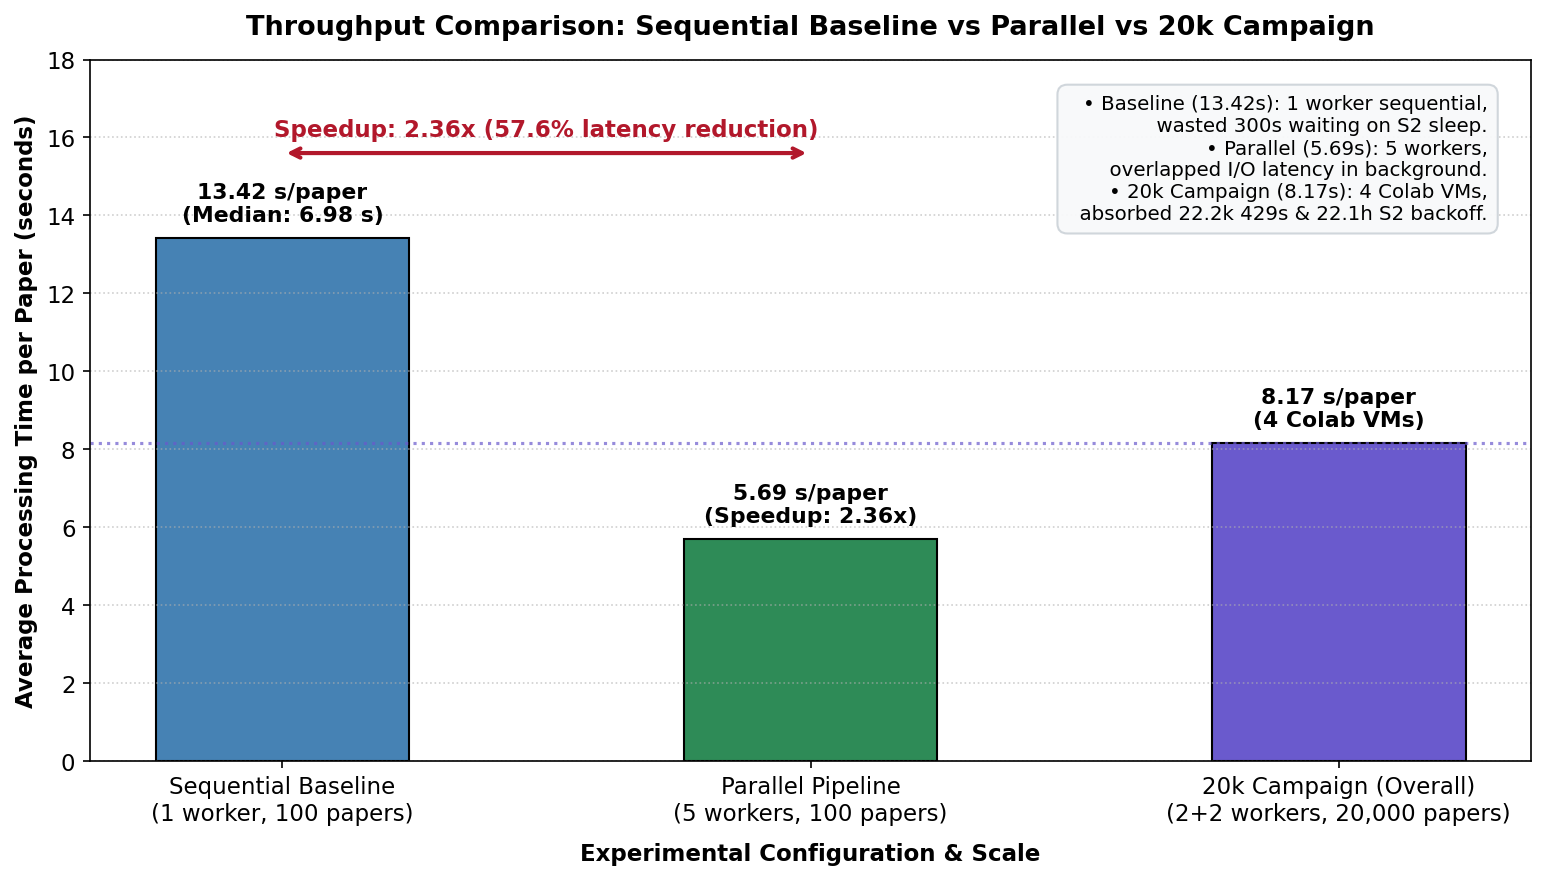

In [4]:
# ─── Figure 3: Throughput Comparison: Baseline vs Parallel vs 20k Campaign ───
plt.rcParams.update({'font.size': 11})

categories = [
    "Sequential Baseline\n(1 worker, 100 papers)",
    "Parallel Pipeline\n(5 workers, 100 papers)",
    "20k Campaign (Overall)\n(2+2 workers, 20,000 papers)"
]
avg_times = [
    BASELINE["avg_per_paper_s"],
    PARALLEL_100["avg_per_paper_s"],
    CAMPAIGN["per_paper_s"]
]
colors = ["#4682B4", "#2E8B57", "#6A5ACD"]

fig, ax = plt.subplots(figsize=(10.5, 6.0), dpi=150)

bars = ax.bar(categories, avg_times, color=colors, edgecolor="black", width=0.48)

# Bar labels
labels = [
    f"{BASELINE['avg_per_paper_s']:.2f} s/paper\n(Median: {BASELINE['median_per_paper_s']:.2f} s)",
    f"{PARALLEL_100['avg_per_paper_s']:.2f} s/paper\n(Speedup: 2.36x)",
    f"{CAMPAIGN['per_paper_s']:.2f} s/paper\n(4 Colab VMs)"
]

for bar, label in zip(bars, labels):
    yval = bar.get_height()
    ax.annotate(label,
                xy=(bar.get_x() + bar.get_width() / 2, yval),
                xytext=(0, 6), textcoords="offset points",
                ha="center", va="bottom", fontsize=10.5, fontweight="bold")

# Add speedup comparison bracket between Baseline and Parallel
ax.annotate("", xy=(0, 15.6), xytext=(1, 15.6),
            arrowprops=dict(arrowstyle="<->", color="#b2182b", lw=2.0))
ax.text(0.5, 15.9, "Speedup: 2.36x (57.6% latency reduction)", ha="center", va="bottom", 
        fontsize=11, fontweight="bold", color="#b2182b")

# Reference dashed line for 20k campaign
ax.axhline(CAMPAIGN["per_paper_s"], color="#6A5ACD", linestyle=":", linewidth=1.5, alpha=0.7)

ax.set_ylabel("Average Processing Time per Paper (seconds)", fontsize=11, fontweight="bold")
ax.set_xlabel("Experimental Configuration & Scale", fontsize=11, fontweight="bold", labelpad=8)
ax.set_title("Throughput Comparison: Sequential Baseline vs Parallel vs 20k Campaign", fontsize=13, fontweight="bold", pad=12)
ax.set_ylim(0, 18.0)
ax.grid(axis="y", linestyle=":", alpha=0.6)

# Text box explaining difference between 100 papers and 20k papers
explanation = (
    "• Baseline (13.42s): 1 worker sequential,\n"
    "  wasted 300s waiting on S2 sleep.\n"
    "• Parallel (5.69s): 5 workers,\n"
    "  overlapped I/O latency in background.\n"
    "• 20k Campaign (8.17s): 4 Colab VMs,\n"
    "  absorbed 22.2k 429s & 22.1h S2 backoff."
)
props = dict(boxstyle="round,pad=0.5", facecolor="#f8f9fa", edgecolor="#ced4da", alpha=0.95)
ax.text(0.97, 0.95, explanation, transform=ax.transAxes, fontsize=9.5, 
        verticalalignment="top", horizontalalignment="right", bbox=props)

plt.tight_layout()
plt.show()


In [5]:
# ─── Summary Table of Key Performance Metrics ───
metrics = pd.DataFrame({
    "Performance Metric": [
        "Total Target Papers Scraped",
        "Successful Acquisition Rate (SUCCESS)",
        "PDF-only Papers Rate (PDF_ONLY)",
        "Network Interruption Rate (INCOMPLETE)",
        "Unrecoverable Loss Rate (FAILED)",
        "Average Processing Time per Paper",
        "Total Campaign Calendar Duration",
        "Total Machine Time (4 VMs Combined)",
        "Peak Memory Footprint (Peak RSS)",
        "Weighted Average Memory Usage",
        "Raw Ingress Volume from arXiv",
        "Extracted LaTeX/Bib Storage Footprint",
        "Final Handover Dataset Footprint (Papers + Refs)",
        "Storage Compression Savings Ratio",
        "Semantic Scholar HTTP 429 Rate-Limit Hits",
        "Cumulative Exponential Backoff Sleep Duration",
        "Throughput Optimization (Parallel vs Baseline)",
    ],
    "Empirical Value": [
        "20,000 papers",
        "91.44% (18,287 papers)",
        "8.55% (1,711 papers)",
        "0.01% (2 papers)",
        "0.00% (0 papers)",
        "8.17 s/paper (8.1657 s)",
        "70.12 hours (Nov 13 13:03 → Nov 16 11:10 UTC)",
        "49.19 hours (177,090 seconds)",
        "51.22 MiB",
        "45.69 MiB",
        "147.97 GB",
        "10.93 GB",
        "12.08 GB",
        "92.61% (137.04 GB saved)",
        "22,238 occurrences",
        "22.12 hours (79,614 seconds across 4 VMs)",
        "2.36x (13.42s → 5.69s/paper)",
    ]
})

display(metrics)


,Performance Metric,Empirical Value
0,Total Target Papers Scraped,"20,000 papers"
1,Successful Acquisition Rate (SUCCESS),"91.44% (18,287 papers)"
2,PDF-only Papers Rate (PDF_ONLY),"8.55% (1,711 papers)"
3,Network Interruption Rate (INCOMPLETE),0.01% (2 papers)
4,Unrecoverable Loss Rate (FAILED),0.00% (0 papers)
5,Average Processing Time per Paper,8.17 s/paper (8.1657 s)
6,Total Campaign Calendar Duration,70.12 hours (Nov 13 13:03 → Nov 16 11:10 UTC)
7,Total Machine Time (4 VMs Combined),"49.19 hours (177,090 seconds)"
8,Peak Memory Footprint (Peak RSS),51.22 MiB
9,Weighted Average Memory Usage,45.69 MiB


## 5. Technical Bottlenecks & System Analysis

Based on telemetry aggregated across 4 virtual machines over 20,000 papers, the system exhibited three primary technical bottlenecks:

### 1. Network I/O Bottleneck (Download Phase: 67.1% of Cumulative Execution Time)
- **Root Cause:** arXiv enforces strict rate-limiting policies (up to 1 request / 3 seconds per client IP). Furthermore, each compressed `.tar.gz` package containing complete LaTeX source, `.bib` bibliographies, and figures averages **~7.5 MB**. Public network throughput between Google Colab compute nodes and `export.arxiv.org` fluctuated significantly, causing per-paper download latencies to range between **1.5 seconds and over 70 seconds**.
- **Data Volume:** Total ingress volume for the 20,000 papers reached **147.97 GB** over HTTP. This represents an inherent physical network bound that cannot be mitigated by scaling CPU cores or optimizing compute routines.
- **Mitigation:** The pipeline deploys 2 independent Download Workers to enable I/O pipelining (pipelined overlap). The primary worker ingests the subsequent paper while the secondary worker decompresses the active payload, eliminating CPU idle states.

### 2. Rate-Limit Contention & Backoff at Semantic Scholar (S2 Phase: 25.7% Time + 22,238 HTTP 429 Errors)
- **Root Cause:** Each node deployed 2 concurrent S2 Workers sharing a single Semantic Scholar API Key (with a theoretical limit of 1 request/second). Client-side rate limiting (`s2_rate_limiter.min_interval = 1.0s`) regulated local dispatch intervals but did not account for network round-trip time (RTT jitter between Colab and S2 servers fluctuated between 50–100ms). Consequently, requests dispatched within the same process occasionally arrived at the server within sub-second intervals, triggering `HTTP 429 Too Many Requests`.
- **Empirical Impact:** Telemetry logged **22,238 HTTP 429 occurrences** against **20,108 successful queries (HTTP 200)** (a ratio of 1.11 errors per success). Cumulative exponential backoff sleep totaled **22.12 machine hours** (79,614 seconds across 4 VMs), accounting for more than half of the citation collection phase.
- **Architectural Lesson:** Adding a safety buffer (`min_interval = 1.15s`) absorbs network jitter, or alternatively, delegating API queries to a serialized worker when operating under a single API key prevents client-side lockstep collisions.

### 3. Google Colab 12-Hour Session Cutoff & Distributed Synchronization
- **Root Cause:** Google Colab CPU runtimes terminate instances after 12 continuous hours or following brief idle disconnections. The 20,000-paper campaign required a cumulative 49.2 machine hours (~11.3 machine hours per 5,000-paper partition). This runtime closely bordered Colab's maximum session limit, introducing severe preemption risk.
- **Empirical Evidence:** The system recorded **889 heartbeat/attempt entries** across 20,000 papers (~44.4 papers per attempt), confirming frequent environment preemptions and restarts.
- **Mitigation:** The Shared Journal model paired with 25-paper checkpoint commits to GitHub provided complete idempotency. Upon preemption, a newly initialized Colab runtime executed `git pull` in seconds, identified the exact uncommitted boundary, and resumed execution without data loss.


## 6. Technical Roadmap & Future Improvements

Drawing upon lessons learned from the distributed benchmark campaign, we identify five concrete optimization trajectories for academic data pipelines:

| Technical Improvement | Estimated Impact / Resource Savings | Implementation Feasibility |
|---|---|---|
| **Serialize S2 Worker (2 threads $\rightarrow$ 1 thread) per Shared API Key** | Eliminates 22,238 HTTP 429 retries and lockstep thread contention; saves an estimated **15–20% of S2 duration** (~3.5–4.5 machine hours). | ✅ Very High (1 configuration line) |
| **Network Jitter Buffer (`min_interval = 1.15s`)** | Prevents boundary violations caused by Colab RTT latency variance; saves **~5% of S2 duration**. | ✅ Very High (Single constant update) |
| **Migrate to Semantic Scholar Batch API (`POST /graph/v1/paper/batch`)** | Enables up to 500 papers per batch request; reduces API calls from 5,000 to **10 requests** (99.8% reduction in citation I/O overhead). | ✅ Medium (Refactor `references.py`) |
| **Deploy on Dedicated Cloud Server / VPS** | Eliminates Google Colab's 12-hour session limit and removes distributed checkpoint synchronization overhead. | ⚠️ Medium (Requires provisioned infrastructure) |
| **Streaming In-Memory Decompression (`tarfile.open(mode='r:gz')`)** | Extracts `.tex` / `.bib` files directly from memory streams during download; reduces transient disk footprint from **148 GB** to **~11 GB**. | ✅ Medium (Refactor `downloader.py`) |


## 7. Conclusion

The 20,000 arXiv paper benchmark campaign for Milestone 1 concluded with rigorous empirical findings:

1. **Academic Scraping Success Rate of 91.44%:** Successfully acquired full LaTeX source packages, publication metadata, and citation graphs for 18,287 papers. The remaining 8.55% `PDF_ONLY` papers reflect author submission characteristics on arXiv rather than crawler deficiencies.
2. **Substantial Multithreaded Speedup:** The multithreaded Producer-Consumer architecture delivered a **2.36x speedup** over sequential scraping (decreasing average latency from 13.42 s/paper to 5.69 s/paper on standard 100-paper benchmarks).
3. **Resilient Distributed Execution:** GitHub-orchestrated Shared Journal checkpoints fully resolved Google Colab's 12-hour preemption constraint, completing 20,000 papers with zero unrecoverable losses (`FAILED = 0`).
4. **Data Engineering Profile:** Telemetry validates that this workload is strictly **Network I/O- and rate-limit bound** (accounting for 92.8% of runtime: 67.1% Download + 25.7% S2), while CPU computation and memory footprints remain minimal (Peak RSS of only 51.22 MiB).

The entire distributed campaign of 20,000 papers was successfully executed on free public cloud resources (Google Colab CPU + GitHub) at an overall financial expenditure of **$0**.
